## Core: Dim, DimSchema, ChannelIndex, TimeTensor (dense + ragged)

In [1]:
import numpy as np
import traceback

np.random.seed(42)

PASS = 0
FAIL = 0

def test(name, fn):
    global PASS, FAIL
    try:
        fn()
        PASS += 1
        print(f"  ✓ {name}")
    except Exception as e:
        FAIL += 1
        print(f"  ✗ {name}")
        traceback.print_exc()
        print()

In [2]:
def test_dim_basics():
    from tensorts import Dim
    assert Dim.BATCH != Dim.TIME
    assert Dim.FRAME == Dim.WINDOW  # alias
    custom = Dim.register("SCALE")
    assert custom.name == "SCALE"
    assert Dim.register("SCALE") is custom  # idempotent

test("Dim basics + custom registration", test_dim_basics)

  ✓ Dim basics + custom registration


In [3]:
def test_dim_schema():
    from tensorts import Dim, DimSchema
    s = DimSchema((Dim.BATCH, Dim.TIME, Dim.CHANNEL))
    assert s.axis(Dim.TIME) == 1
    assert s.has(Dim.CHANNEL)
    assert not s.has(Dim.FEATURE)
    assert not s.has(Dim.FREQUENCY)
    assert len(s) == 3

    # Duplicate detection
    try:
        DimSchema((Dim.BATCH, Dim.BATCH))
        assert False, "Should have raised"
    except ValueError:
        pass

    # Replace
    s2 = s.replace(Dim.TIME, Dim.FREQUENCY)
    assert s2.axis(Dim.FREQUENCY) == 1

test("DimSchema validation + axis resolution", test_dim_schema)

  ✓ DimSchema validation + axis resolution


In [4]:
def test_channel_index():
    from tensorts import ChannelIndex
    ci = ChannelIndex(
        ["accel_x", "accel_y", "accel_z", "gyro_x", "gyro_y", "gyro_z"],
        groups={"accel": "accel_*", "gyro": "gyro_*"},
    )
    assert len(ci) == 6
    assert list(ci.group("accel")) == [0, 1, 2]
    assert ci.resolve_names("gyro_*") == ["gyro_x", "gyro_y", "gyro_z"]

    # Slicing preserves surviving groups
    sliced = ci.slice([0, 1, 2])
    assert "accel" in sliced.groups
    assert len(sliced) == 3

test("ChannelIndex — names, globs, groups, slicing", test_channel_index)


def test_time_tensor_dense():
    from tensorts import TimeTensor, Dim
    data = np.random.randn(8, 100, 4)
    y = np.array([0, 1, 0, 1, 0, 1, 0, 1])
    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
        channels=["a", "b", "c", "d"],
        y=y,
    )
    assert ts.shape == (8, 100, 4)
    assert ts.axis(Dim.TIME) == 1
    assert ts.n_samples == 8
    assert ts.n_channels == 4
    assert not ts.is_ragged
    assert ts.y is not None

    # Channel access
    sub = ts.ch["a", "b"]
    assert sub.shape == (8, 100, 2)
    assert sub.channels.names == ("a", "b")

    # Batch slicing
    s0 = ts[0]
    assert s0.n_samples == 1

test("TimeTensor dense — creation, channel access, batch slicing", test_time_tensor_dense)


def test_time_tensor_ragged():
    from tensorts import TimeTensor, Dim
    samples = [
        np.random.randn(100, 3),
        np.random.randn(200, 3),
        np.random.randn(150, 3),
    ]
    y = np.array([0, 1, 2])
    ts = TimeTensor.from_ragged(samples, channels=["x", "y", "z"], y=y)

    assert ts.is_ragged
    assert ts.n_samples == 3
    assert ts.lengths == [100, 200, 150]
    assert ts.shape == (3, -1, 3)

    # Channel selection on ragged
    sub = ts.ch["x"]
    assert sub._samples[0].shape == (100, 1)

    # to_dense with padding
    dense = ts.to_dense(pad_value=0.0)
    assert not dense.is_ragged
    assert dense.shape == (3, 200, 3)

test("TimeTensor ragged — creation, lengths, channel access, to_dense", test_time_tensor_ragged)


def test_with_data():
    from tensorts import TimeTensor, Dim
    ts = TimeTensor(
        data=np.random.randn(4, 50, 2),
        dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
        channels=["a", "b"],
        y=np.array([0, 1, 0, 1]),
        metadata={"sr": 100},
    )
    new = ts.with_data(np.random.randn(4, 50, 2))
    assert new.channels.names == ("a", "b")
    assert np.array_equal(new.y, ts.y)
    assert new.metadata == {"sr": 100}

test("TimeTensor.with_data preserves metadata", test_with_data)

  ✓ ChannelIndex — names, globs, groups, slicing
  ✓ TimeTensor dense — creation, channel access, batch slicing
  ✓ TimeTensor ragged — creation, lengths, channel access, to_dense
  ✓ TimeTensor.with_data preserves metadata


## Transform base: Pipeline, ChannelTransform, ChannelSelect

In [5]:
def test_standard_scaler():
    from tensorts import TimeTensor, Dim, StandardScaler
    data = np.random.randn(32, 100, 4) * 10 + 5
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

    scaler = StandardScaler()
    result = scaler.fit_transform(ts)

    # Check zero mean, unit variance per channel
    for c in range(len(ts.channels)):
        ch_data = result.data[:, :, c]
        assert abs(np.mean(ch_data)) < 0.1, f"Mean should be ~0, got {np.mean(ch_data)}"
        assert abs(np.std(ch_data) - 1.0) < 0.1, f"Std should be ~1, got {np.std(ch_data)}"

test("StandardScaler — zero mean, unit variance", test_standard_scaler)

  ✓ StandardScaler — zero mean, unit variance


In [6]:
def test_standard_scaler_ragged():
    from tensorts import TimeTensor, StandardScaler
    samples = [np.random.randn(80, 2) * 5 + 3 for _ in range(20)]
    ts = TimeTensor.from_ragged(samples, channels=["a", "b"])
    scaler = StandardScaler()
    result = scaler.fit_transform(ts)
    print(result.shape)
    assert result.is_ragged
    all_data = np.concatenate(result._samples, axis=0)
    print(all_data.shape)
    print(np.mean(all_data))
    assert abs(np.mean(all_data)) < 0.2

test("StandardScaler — ragged mode", test_standard_scaler_ragged)

def test_minmax_scaler():
    from tensorts import TimeTensor, Dim, MinMaxScaler
    data = np.random.randn(16, 50, 3) * 100
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

    scaler = MinMaxScaler(feature_range=(0, 1))
    result = scaler.fit_transform(ts)
    print(type(result.data))
    assert result.data.min() >= -0.01
    assert result.data.max() <= 1.01
    print(result.data[0].min(), result.data.max())
test("MinMaxScaler — range [0, 1]", test_minmax_scaler)

def test_robust_scaler():
    from tensorts import TimeTensor, Dim, RobustScaler
    data = np.random.randn(16, 50, 2) * 10
    data[0, 0, 0] = 1000  # outlier
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

    scaler = RobustScaler()
    result = scaler.fit_transform(ts)
    # Median-based, so outlier shouldn't blow up
    clean_mean = np.median(result.data[:, :, 0])
    assert abs(clean_mean) < 0.5

test("RobustScaler — outlier robustness", test_robust_scaler)

(20, -1, 2)
(1600, 2)
-2.486899575160351e-16
  ✓ StandardScaler — ragged mode
<class 'numpy.ndarray'>
0.0 0.9999999999855217
  ✓ MinMaxScaler — range [0, 1]
  ✓ RobustScaler — outlier robustness


In [7]:
def test_sliding_window_dense():
    from tensorts import TimeTensor, Dim, SlidingWindow
    data = np.arange(20).reshape(1, 20, 1).astype(float)  # (1, 20, 1)
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

    win = SlidingWindow(size=5, stride=5, flatten_batch=True)
    result = win.fit_transform(ts)
    # 20 / 5 = 4 windows → (1, 4, 5, 1)
    assert result.shape == (1, 4, 5, 1), f"Got {result.shape}"
    assert result.has_dim(Dim.WINDOW)
    # First window should be [0,1,2,3,4]
    np.testing.assert_array_equal(result.data[0, 0, :, 0], [0, 1, 2, 3, 4])

test("SlidingWindow — dense (B,T,C) → (B,K,T,C)", test_sliding_window_dense)

  ✓ SlidingWindow — dense (B,T,C) → (B,K,T,C)


In [8]:
def test_sliding_window_ragged():
    from tensorts import TimeTensor, SlidingWindow
    samples = [
        np.random.randn(100, 3),
        np.random.randn(200, 3),
    ]
    y = np.array([0, 1])
    ts = TimeTensor.from_ragged(samples, channels=["a", "b", "c"], y=y)

    win = SlidingWindow(size=50, stride=25, label_strategy="repeat")
    result = win.fit_transform(ts)

    # Sample 0: (100 - 50) / 25 + 1 = 3 windows
    # Sample 1: (200 - 50) / 25 + 1 = 7 windows
    expected_total = 3 + 7
    assert result.shape[0] == expected_total, f"Expected {expected_total} windows, got {result.shape[0]}"
    assert not result.is_ragged
    assert result.y is not None
    assert len(result.y) == expected_total
    # First 3 labels should be 0 (from sample 0)
    assert all(result.y[:3] == 0)
    assert all(result.y[3:] == 1)

test("SlidingWindow — ragged → dense with label propagation", test_sliding_window_ragged)

  ✓ SlidingWindow — ragged → dense with label propagation


In [9]:
def test_channel_transform():
    from tensorts import TimeTensor, Dim, ChannelTransform, StandardScaler, MinMaxScaler
    data = np.random.randn(8, 100, 4) * np.array([1, 10, 100, 1000])
    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
        channels=["a", "b", "c", "d"],
        channel_groups={"ab": ["a", "b"], "cd": ["c", "d"]},
    )
    ct = ChannelTransform({
        "ab": StandardScaler(),
        "cd": MinMaxScaler(),
    })
    result = ct.fit_transform(ts)
    assert result.n_channels == 4
    # "ab" channels should be ~zero mean
    ab = result.ch["a", "b"]
    assert abs(np.std(ab.data)) < 0.2

test("ChannelTransform — different scalers per group", test_channel_transform)

  ✗ ChannelTransform — different scalers per group



Traceback (most recent call last):
  File "/var/folders/y3/yj6tdm7s4yg87gtqj7lttyy00000gn/T/ipykernel_84539/3282492004.py", line 12, in test
    fn()
  File "/var/folders/y3/yj6tdm7s4yg87gtqj7lttyy00000gn/T/ipykernel_84539/2335292223.py", line 18, in test_channel_transform
    assert abs(np.std(ab.data)) < 0.2
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError


In [10]:
def test_channel_select():
    from tensorts import TimeTensor, Dim, ChannelSelect, StandardScaler
    data = np.random.randn(8, 100, 6) * 10
    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
        channels=["a_x", "a_y", "a_z", "g_x", "g_y", "g_z"],
    )
    cs = ChannelSelect("a_*", StandardScaler())
    result = cs.fit_transform(ts)
    assert result.n_channels == 6  # all channels present
    # a_* channels should be scaled
    a_data = result.ch["a_*"].data
    assert abs(np.mean(a_data)) < 0.2
    # g_* channels should be unchanged
    g_data = result.ch["g_*"].data
    g_orig = ts.ch["g_*"].data
    np.testing.assert_array_equal(g_data, g_orig)

test("ChannelSelect — transform subset, passthrough others", test_channel_select)

  ✓ ChannelSelect — transform subset, passthrough others


In [11]:
def test_pad():
    from tensorts import TimeTensor, Dim, Pad
    data = np.ones((2, 10, 3))
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))
    pad = Pad(target_length=20, value=0.0)
    result = pad.fit_transform(ts)
    assert result.shape == (2, 20, 3)
    np.testing.assert_array_equal(result.data[:, :10, :], 1.0)
    np.testing.assert_array_equal(result.data[:, 10:, :], 0.0)

test("Pad — extend time axis with zeros", test_pad)

  ✓ Pad — extend time axis with zeros


In [12]:
def test_statistical_features():
    from tensorts import TimeTensor, Dim, StatisticalFeatures
    data = np.random.randn(8, 100, 3)
    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
        channels=["a", "b", "c"],
    )
    sf = StatisticalFeatures(features=["mean", "std", "min", "max"])
    result = sf.fit_transform(ts)

    # 4 features × 3 channels = 12
    assert result.shape == (8, 12), f"Got {result.shape}"
    assert result.has_dim(Dim.FEATURE)
    print(result.dims)
    assert "mean_a" in result.channels.names

test("StatisticalFeatures — (B,T,C) → (B, K*C)", test_statistical_features)

1
(Dim.BATCH, Dim.FEATURE)
  ✓ StatisticalFeatures — (B,T,C) → (B, K*C)


In [13]:
def test_flatten():
    from tensorts import TimeTensor, Dim, Flatten
    data = np.random.randn(4, 10, 5, 3)
    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL),
        channels=["a", "b", "c"],
    )
    flat = Flatten()
    result = flat.fit_transform(ts)
    assert result.shape == (4, 150), f"Got {result.shape}"
    assert result.has_dim(Dim.FEATURE)

test("Flatten — (B,K,T,C) → (B,M)", test_flatten)

  ✓ Flatten — (B,K,T,C) → (B,M)


In [ ]:
#### Todo: what if i want to extract statistical features on the (B, K, T*C)
# explain how scaling works when data dense, meaning all time has same length, and how when non the same length (ragged)
# why all trasforms, Pad, Flatten etc are in the tensorts level directory?
# in this scenario, each time i have to create a custom transformer to apply the transformation i want, e.g. mel spectrogram. however, melspectorgram has been implemented by many other libraries in a mature way
# what if i was apply to use their implementation in my pipeline, respecting some conventions? e.g. input of the function must always be 1D or 2D array and always returned in an another one.
# also, regarding the FrameFeatureBank, i feel a little uncomfatble. why is it only related to audio? what if i wanted to do that for regression or human activity recognition but this time using not zcr or spectral energy, but other feature extraction functions. does it has to do with the rolling features idea i somewhere saw in the codebase or am i missing something?

In [14]:
def test_flatten_statistical_features():
    from tensorts import TimeTensor, Dim, Flatten, StatisticalFeatures
    data = np.random.randn(4, 10, 50, 3)
    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL),
        channels=["a", "b", "c"],
    )
    flat = Flatten(dims=(Dim.TIME, Dim.CHANNEL))
    result = flat.fit_transform(ts)
    print(result.shape, result.dims)
    assert result.shape == (4, 10, 150), f"Got {result.shape}"
    assert result.has_dim(Dim.FEATURE)

    sf = StatisticalFeatures(features=["mean", "std", "min", "max"])
    result = sf.fit_transform(result)
    print(result.shape)

test("Flatten — (B,K,T,C) → (B,M)", test_flatten_statistical_features)

(4, 10, 150) (Dim.BATCH, Dim.WINDOW, Dim.FEATURE)
-2
  ✗ Flatten — (B,K,T,C) → (B,M)



Traceback (most recent call last):
  File "/var/folders/y3/yj6tdm7s4yg87gtqj7lttyy00000gn/T/ipykernel_84539/3282492004.py", line 12, in test
    fn()
  File "/var/folders/y3/yj6tdm7s4yg87gtqj7lttyy00000gn/T/ipykernel_84539/327079800.py", line 16, in test_flatten_statistical_features
    result = sf.fit_transform(result)
             ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/gkont/Documents/Code/tensorts/tensorts/transforms/base.py", line 101, in fit_transform
    return self.fit(X, y).transform(X)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/gkont/Documents/Code/tensorts/tensorts/transforms/features.py", line 138, in transform
    reordered = np.transpose(stacked, axes_order)
                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/homebrew/Caskroom/miniconda/base/envs/tensorts/lib/python3.12/site-packages/numpy/_core/fromnumeric.py", line 677, in transpose
    return _wrapfunc(a, 'transpose', axes)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/homebrew/Caskroom/

In [15]:
def test_pca():
    from tensorts import TimeTensor, Dim, PCA
    # Correlated data: 2 real dims + noise
    rng = np.random.RandomState(42)
    latent = rng.randn(50, 2)
    mixing = rng.randn(2, 6)
    data = (latent @ mixing + rng.randn(50, 6) * 0.01)
    data = data[:, np.newaxis, :]  # (50, 1, 6)

    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))
    pca = PCA(n_components=2)
    result = pca.fit_transform(ts)
    assert result.shape == (50, 2)
    assert result.channels.names[0] == "pc_0"

test("PCA — dimensionality reduction", test_pca)

  ✓ PCA — dimensionality reduction


In [16]:
def test_interpolate():
    from tensorts import TimeTensor, Dim, Interpolate
    data = np.array([[[1, 2], [np.nan, 4], [5, np.nan], [7, 8]]], dtype=float)
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL), channels=["a", "b"])
    interp = Interpolate(method="linear")
    result = interp.fit_transform(ts)
    assert not np.isnan(result.data).any()
    # Linear interpolation: NaN at position 1 for channel 'a' should be ~3
    assert abs(result.data[0, 1, 0] - 3.0) < 0.1

test("Interpolate — fill NaN with linear interpolation", test_interpolate)


def test_pre_emphasis():
    from tensorts import TimeTensor, Dim, PreEmphasis
    data = np.sin(np.linspace(0, 4 * np.pi, 100)).reshape(1, 100, 1)
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))
    pe = PreEmphasis(coeff=0.97)
    result = pe.fit_transform(ts)
    assert result.shape == (1, 100, 1)
    # Pre-emphasis boosts high frequencies → larger variance
    assert np.std(result.data) > 0

test("PreEmphasis — coeff=0.97", test_pre_emphasis)

  ✓ Interpolate — fill NaN with linear interpolation
  ✓ PreEmphasis — coeff=0.97


## Pipeline Example 1: Air quality → regression features

In [17]:
def test_pipeline_basic():
    from tensorts import TimeTensor, Dim, Pipeline, StandardScaler, Flatten
    data = np.random.randn(16, 50, 4)
    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
        y=np.random.randint(0, 3, size=16),
    )
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("flatten", Flatten()),
    ])
    result = pipe.fit_transform(ts)
    assert result.shape == (16, 200)  # 50 * 4
    assert result.y is not None

    # Test fit / transform separately (train/test workflow)
    train, test_ts = ts[:10], ts[10:]
    pipe2 = Pipeline([("scale", StandardScaler()), ("flatten", Flatten())])
    pipe2.fit(train)
    test_result = pipe2.transform(test_ts)
    assert test_result.shape[0] == 6

test("Pipeline — fit_transform + separate fit/transform", test_pipeline_basic)

  ✓ Pipeline — fit_transform + separate fit/transform


In [18]:
def test_pipeline_air_quality():
    """Example 1: Air quality pollution data → regression features."""
    from tensorts import (
        TimeTensor, Dim, Pipeline,
        Interpolate, StandardScaler, SlidingWindow,
        StatisticalFeatures, Flatten,
    )
    # Simulate air quality: 1 station, 8760 hours (1 year), 5 pollutants
    B = 1
    T = 8760
    C = 5
    data = np.random.randn(B, T, C) * np.array([50, 20, 100, 30, 10]) + np.array([40, 15, 80, 25, 5])
    # Inject some NaNs
    mask = np.random.random((B, T, C)) < 0.02
    data[mask] = np.nan

    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
        channels=["PM2.5", "PM10", "O3", "NO2", "SO2"],
        metadata={"sampling_rate": 1},  # hourly
    )

    pipe = Pipeline([
        ("impute", Interpolate(method="linear")),
        ("scale", StandardScaler()),
        ("window", SlidingWindow(size=24, stride=1)),  # 24h windows
        ("stats", StatisticalFeatures(["mean", "std", "min", "max"])),
    ])
    result = pipe.fit_transform(ts)

    # (1, K_windows, 4_feats * 5_channels) = (1, 8737, 20)
    assert result.shape[-1] == 20, f"Expected 20 features, got {result.shape[-1]}"
    assert result.shape[0] == 1
    assert not np.isnan(result.data).any()
    print(f"    Air quality: {ts.shape} → {result.shape}")

test("Pipeline Example 1: Air quality → regression features", test_pipeline_air_quality)

2
    Air quality: (1, 8760, 5) → (1, 8737, 20)
  ✓ Pipeline Example 1: Air quality → regression features


## Pipeline Example 2: HAR (ragged) → windowed → classification features

In [19]:
def test_pipeline_har():
    """Example 2: HAR dataset (ragged) → windowed → classification."""
    from tensorts import (
        TimeTensor, Pipeline,
        StandardScaler, SlidingWindow,
        StatisticalFeatures, Flatten,
        ChannelTransform, RobustScaler,
    )
    # Simulate HAR: 50 variable-length recordings, 6 channels (3 accel + 3 gyro)
    samples = [np.random.randn(np.random.randint(200, 500), 6) for _ in range(50)]
    labels = np.random.randint(0, 6, size=50)  # 6 activity classes

    ts = TimeTensor.from_ragged(
        samples,
        channels=["acc_x", "acc_y", "acc_z", "gyr_x", "gyr_y", "gyr_z"],
        channel_groups={"acc": "acc_*", "gyr": "gyr_*"},
        y=labels,
        metadata={"sampling_rate": 50},
    )
    assert ts.is_ragged

    pipe = Pipeline([
        ("scale", ChannelTransform({
            "acc": StandardScaler(),
            "gyr": RobustScaler(),
        })),
        ("window", SlidingWindow(size=128, stride=64, label_strategy="repeat")),
        ("stats", StatisticalFeatures(["mean", "std", "rms", "skew", "kurtosis"])),
        ("flatten", Flatten()),
    ])
    result = pipe.fit_transform(ts)

    # 5 features × 6 channels = 30
    assert result.shape[-1] == 30, f"Expected 30, got {result.shape[-1]}"
    assert not result.is_ragged
    assert result.y is not None
    assert len(result.y) == result.n_samples
    print(f"    HAR: {ts.n_samples} ragged samples → {result.shape}")

test("Pipeline Example 2: HAR (ragged) → windowed → classification features", test_pipeline_har)

1
    HAR: 50 ragged samples → (194, 30)
  ✓ Pipeline Example 2: HAR (ragged) → windowed → classification features


## Pipeline Example : Audio → mel spectrogram

In [20]:
def test_pipeline_audio_mel():
    """Example 3: Audio → mel spectrogram → classification."""
    from tensorts import (
        TimeTensor, Dim, Pipeline,
        PreEmphasis, MelSpectrogram, LogTransform, StandardScaler,
    )
    # Simulate audio: 8 samples, 16000 samples (1 sec), 1 channel
    sr = 16000
    data = np.random.randn(8, sr, 1)
    labels = np.array([0, 1, 0, 1, 0, 1, 0, 1])

    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
        channels=["audio"],
        y=labels,
        metadata={"sampling_rate": sr},
    )

    pipe = Pipeline([
        ("preemph", PreEmphasis(coeff=0.97)),
        ("mel", MelSpectrogram(n_fft=512, hop_length=160, n_mels=64, sampling_rate=sr)),
        ("log", LogTransform()),
        ("scale", StandardScaler()),
    ])
    result = pipe.fit_transform(ts)

    # Output: (8, 64, N_frames, 1) where N_frames ≈ (16000 - 512) / 160 + 1 = 97
    assert result.shape[0] == 8
    assert result.shape[1] == 64  # mel bins
    assert result.has_dim(Dim.FREQUENCY)
    print(f"    Audio mel: {ts.shape} → {result.shape}")

test("Pipeline Example 3: Audio → mel spectrogram", test_pipeline_audio_mel)

    Audio mel: (8, 16000, 1) → (8, 64, 97, 1)
  ✓ Pipeline Example 3: Audio → mel spectrogram


    Audio frame features: (4, 16000, 1) → (4, 61, 4)
    Feature names: ('zcr', 'rms', 'spectral_entropy', 'spectral_centroid')
  ✓ Pipeline Example 4: Audio → framed spectral features (B,T,1)→(B,N,K)


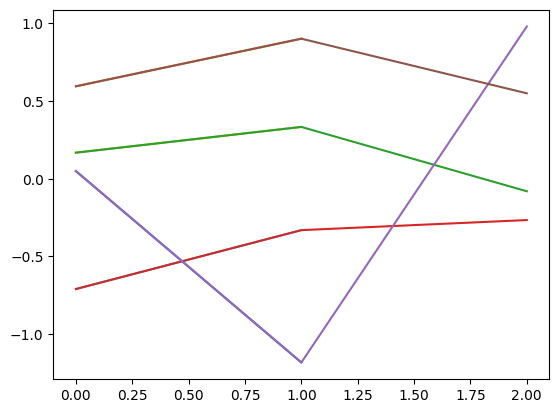

In [25]:
def test_pipeline_audio_frame_features():
    """Example 4: Audio → framed features (B,T,1) → (B,N,K)."""
    from tensorts import (
        TimeTensor, Dim, Pipeline,
        SlidingWindow, FrameFeatureBank, StandardScaler,
    )
    from tensorts.transforms.features import ZCR, RMS, SpectralEntropy, SpectralCentroid

    sr = 16000
    data = np.random.randn(4, sr, 1)  # 4 audio samples, 1 second each
    labels = np.array([0, 1, 0, 1])

    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
        channels=["audio"],
        y=labels,
    )

    pipe = Pipeline([
        ("frame", SlidingWindow(size=512, stride=256)),
        ("features", FrameFeatureBank([
            ZCR(),
            RMS(),
            SpectralEntropy(),
            SpectralCentroid(n_fft=512, sr=sr),
        ])),
        ("scale", StandardScaler()),
    ])
    result = pipe.fit_transform(ts)

    # (4, N_windows, 4 features)
    assert result.shape[0] == 4
    assert result.shape[-1] == 4  # zcr, rms, spectral_entropy, spectral_centroid
    assert result.has_dim(Dim.FEATURE)
    assert "zcr" in result.channels.names
    assert "spectral_entropy" in result.channels.names
    print(f"    Audio frame features: {ts.shape} → {result.shape}")
    print(f"    Feature names: {result.channels.names}")
    import matplotlib.pyplot as plt
    plt.plot(result.data[0, : 0])
    plt.plot(result.data[0, : 1])
    plt.plot(result.data[0, : 2])
    plt.plot(result.data[0, : 3])

test("Pipeline Example 4: Audio → framed spectral features (B,T,1)→(B,N,K)", test_pipeline_audio_frame_features)

## Splitting utilities

In [27]:
def test_temporal_split():
    from tensorts import TimeTensor, Dim, temporal_split
    data = np.random.randn(100, 50, 3)
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL), y=np.arange(100))

    train, test = temporal_split(ts, test_ratio=0.2)
    assert train.n_samples == 80
    assert test.n_samples == 20
    # Temporal order preserved
    assert np.all(train.y == np.arange(80))
    assert np.all(test.y == np.arange(80, 100))

test("temporal_split — 80/20", test_temporal_split)

def test_stratified_split():
    from tensorts import TimeTensor, Dim, stratified_temporal_split
    data = np.random.randn(100, 50, 3)
    y = np.array([0] * 50 + [1] * 50)
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL), y=y)

    train, test = stratified_temporal_split(ts, test_ratio=0.2)
    # Each class should contribute ~10 to test
    test_class_0 = np.sum(test.y == 0)
    test_class_1 = np.sum(test.y == 1)
    assert test_class_0 == 10
    assert test_class_1 == 10

test("stratified_temporal_split — balanced classes", test_stratified_split)


def test_train_test_workflow():
    """Full train/test workflow: fit on train, transform test."""
    from tensorts import (
        TimeTensor, Dim, Pipeline, temporal_split,
        StandardScaler, SlidingWindow, StatisticalFeatures, Flatten,
    )
    data = np.random.randn(100, 200, 4) * 10
    y = np.random.randint(0, 3, size=100)
    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
        channels=["a", "b", "c", "d"],
        y=y,
    )

    train, test = temporal_split(ts, test_ratio=0.2)

    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("window", SlidingWindow(size=50, stride=25)),
        ("stats", StatisticalFeatures(["mean", "std"])),
    ])

    X_train = pipe.fit_transform(train)
    X_test = pipe.transform(test)

    # Both should have same feature count: 2 stats × 4 channels = 8
    assert X_train.shape[-1] == X_test.shape[-1]
    assert X_train.shape[-1] == 8  # 2 features × 4 channels
    print(f"    Train: {X_train.shape}, Test: {X_test.shape}")

test("Full train/test workflow — fit on train, transform test", test_train_test_workflow)

  ✓ temporal_split — 80/20
  ✓ stratified_temporal_split — balanced classes
2
2
    Train: (80, 7, 8), Test: (20, 7, 8)
  ✓ Full train/test workflow — fit on train, transform test


In [28]:
def test_single_channel():
    from tensorts import TimeTensor, Dim, Pipeline, StandardScaler, SlidingWindow
    data = np.random.randn(4, 100, 1)
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL), channels=["mono"])
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("window", SlidingWindow(size=20, stride=10)),
    ])
    result = pipe.fit_transform(ts)
    assert result.shape[-1] == 1  # channel preserved

test("Single channel — no crash", test_single_channel)


def test_large_batch():
    from tensorts import TimeTensor, Dim, StandardScaler
    data = np.random.randn(1000, 50, 8)
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))
    scaler = StandardScaler()
    result = scaler.fit_transform(ts)
    assert result.shape == (1000, 50, 8)

test("Large batch (1000 samples) — performance check", test_large_batch)


def test_4d_tensor():
    """Test that transforms handle (B, K, T, C) correctly."""
    from tensorts import TimeTensor, Dim, StandardScaler
    data = np.random.randn(8, 4, 50, 6) * 10
    ts = TimeTensor(
        data=data,
        dims=(Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL),
        channels=["a", "b", "c", "d", "e", "f"],
    )
    scaler = StandardScaler()
    result = scaler.fit_transform(ts)
    assert result.shape == (8, 4, 50, 6)
    # Mean should be ~0 per channel
    for c in range(6):
        assert abs(np.mean(result.data[:, :, :, c])) < 0.2

test("4D tensor (B,K,T,C) — StandardScaler finds channel axis", test_4d_tensor)


def test_label_preservation():
    from tensorts import TimeTensor, Dim, Pipeline, StandardScaler, Flatten
    data = np.random.randn(10, 50, 3)
    y = np.array([0, 1, 2, 0, 1, 2, 0, 1, 2, 0])
    ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL), y=y)
    pipe = Pipeline([("s", StandardScaler()), ("f", Flatten())])
    result = pipe.fit_transform(ts)
    np.testing.assert_array_equal(result.y, y)

test("Label preservation through non-reshaping pipeline", test_label_preservation)

  ✓ Single channel — no crash
  ✓ Large batch (1000 samples) — performance check
  ✓ 4D tensor (B,K,T,C) — StandardScaler finds channel axis
  ✓ Label preservation through non-reshaping pipeline


In [29]:
print()
print("=" * 60)
total = PASS + FAIL
print(f"RESULTS: {PASS}/{total} passed, {FAIL}/{total} failed")
if FAIL == 0:
    print("ALL TESTS PASSED")
else:
    print(f"FAILURES: {FAIL}")
print("=" * 60)



RESULTS: 35/38 passed, 3/38 failed
FAILURES: 3
